# 5 · Model adaptation and evaluation

**Tasks 3 and 4, light fine-tuning on a single GPU, then BLEU/chrF and qualitative evaluation.**

Training itself runs as scripts, not in this notebook:

```
python notebooks/run_stage.py --stage baseline
python notebooks/run_stage.py --stage stock     --no-checkpointing
python notebooks/run_stage.py --stage extended  --no-checkpointing
python notebooks/run_stage.py --stage extended  --max-phrase-words 1 --tag words-only --no-checkpointing
python notebooks/compare_runs.py
```

Each stage is a separate process because the three together exceed a 24GB
unified-memory machine while no single one does, and a process that exits
returns everything it held. Each writes `reports/task3_<stage>.json`. This
notebook reads those files, so it needs no GPU and re-runs anywhere.

### The four runs

| run | what it isolates |
|---|---|
| `baseline` | the un-fine-tuned model, zero-shot. The "before". |
| `stock` | what the legal data contributes, with no vocabulary change |
| `extended` | 504 pieces, phrases up to 3 words |
| `extended-words-only` | 498 pieces, whole words only |

The last two share a budget, hyperparameters and initialisation. The only
difference is whether a vocabulary piece may span a word boundary.

In [1]:
from court_mt.notebook import setup

theme = setup()

In [2]:
import json

import pandas as pd

from court_mt import paths, viz

runs = {
    path.stem.removeprefix("task3_"): json.loads(path.read_text(encoding="utf-8"))
    for path in sorted(paths.REPORTS.glob("task3_*.json"))
}
print(f"{len(runs)} runs: {', '.join(runs)}")

4 runs: baseline, extended-words-only, extended, stock


## Quality and token cost together

The brief asks for a before/after on both, and they can move in opposite
directions: a vocabulary that cuts tokens is worthless if it also cuts quality.
That is exactly what happens to one of these runs.

In [3]:
scores = pd.read_csv(paths.REPORTS / "task3_scores.csv")
scores.round(2)

,run,BLEU,chrF,ΔchrF,tokens/sentence,token change,added tokens
0,zero-shot (no fine-tuning),29.910,49.460,0.000,55.120,0.000,0
1,"fine-tuned, stock vocab",34.930,53.210,3.750,55.120,0.000,0
2,"fine-tuned, extended vocab",30.370,49.650,0.190,45.490,-0.170,504
3,"fine-tuned, 498 pieces, words only",34.060,53.280,3.830,49.740,-0.100,498


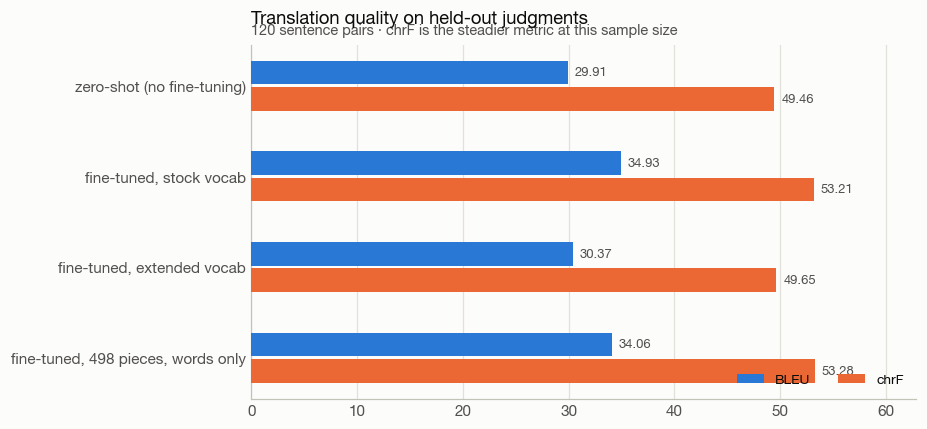

In [4]:
axis = viz.grouped_bar(
    scores.set_index("run")[["BLEU", "chrF"]],
    title="Translation quality on held-out judgments",
    subtitle="120 sentence pairs · chrF is the steadier metric at this sample size",
    theme=theme,
)
viz.save(axis, paths.FIGURES / "task3_quality.png");

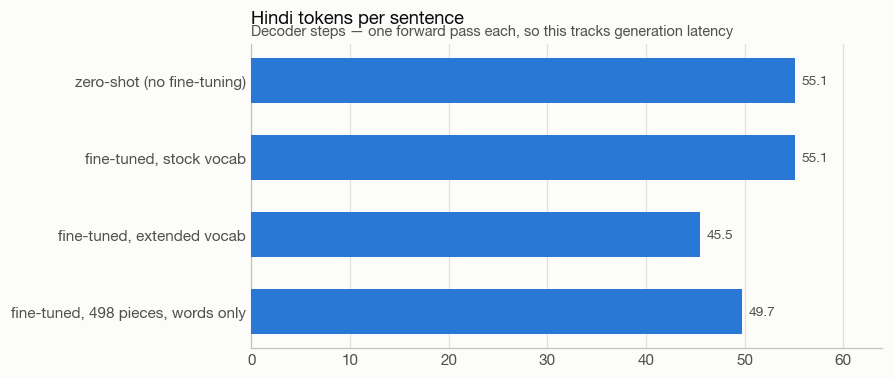

In [5]:
axis = viz.ranked_bar(
    scores.set_index("run")["tokens/sentence"],
    title="Hindi tokens per sentence",
    subtitle="Decoder steps — one forward pass each, so this tracks generation latency",
    value_format="{:.1f}",
    theme=theme,
)
viz.save(axis, paths.FIGURES / "task3_tokens.png");

Three things to read off these.

**Fine-tuning works.** Stock gains 5.02 BLEU and 3.75 chrF over zero-shot on 907
sentence pairs.

**Phrase pieces undo it.** The phrase-based extension saves 17.5% of tokens and
gives back 3.56 chrF, landing barely above the un-fine-tuned baseline.

**Whole-word pieces are free.** Same budget, same settings: 9.8% fewer tokens at
53.28 chrF, which is 53.21 for stock. The difference is inside noise for 120
sentences, and chrF is the metric to trust at that size.

## Where the difference comes from

Comparing what each mining strategy put in the vocabulary explains the gap
better than the scores do.

In [6]:
from court_mt.corpus.dataset import load_corpus, texts
from court_mt.corpus.split import split_corpus
from court_mt.tokenization import extend
from court_mt.tokenization.registry import load_adapters, load_specs

split = split_corpus(load_corpus())
mbart = load_adapters(load_specs(paths.CONFIGS / "tokenizers.yaml", only=["mbart-50"]))[0]

top = {}
for width in (3, 1):
    candidates = extend.mine_candidates(
        texts(split.train, "hi"), mbart,
        require_script="Devanagari", max_phrase_words=width,
    )
    top[f"max {width} words"] = [c.surface for c in candidates[:8]]

pd.DataFrame(top)

INFO    court_mt.corpus.split: split 25 judgments: train 19 (11,7,23,21,3,29,18,30,19,5,15,9,1,16,28,12,24,13,17), dev 3 (4,8,2), test 3 (10,20,27)


/Users/karan/Desktop/adalat-court-mt/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


INFO    court_mt.tokenization.registry: loaded mbart-50               vocab= 250054


INFO    court_mt.tokenization.extend: mined 7022 candidates from 41447 distinct n-grams (54407 tokens saveable)


INFO    court_mt.tokenization.extend: mined 695 candidates from 3146 distinct n-grams (6638 tokens saveable)


,max 3 words,max 1 words
0,के लिए,अपीलकर्ता
1,उच्च न्यायालय,प्रत्यर्थी
2,करने के लिए,सीआरपीसी
3,अपीलकर्ता,इलाहाबाद
4,है कि,एफआईआर
5,किया गया,आक्षेपित
6,किया गया था,मुकदमा
7,के तहत,प्रत्यर्थीगणों


Phrase mining spends its best slots on function-word glue: `के लिए` ("for the"),
`है कि` ("that is"), `किया गया` ("was done"). Those are exactly the pieces a
decoder needs to compose freely, and freezing them into single tokens costs it
that freedom.

Word mining spends the same slots on terms of art: `अपीलकर्ता` (appellant),
`प्रत्यर्थी` (respondent), `सीआरपीसी` (CrPC), `एफआईआर` (FIR). Those have stable
meanings and no compositional role, so a dedicated token loses nothing.

## Qualitative evaluation

Aggregate metrics hide what actually changed. These are the categories the brief
names.

In [7]:
translations = pd.read_csv(paths.REPORTS / "task3_translations.csv")
columns = ["baseline", "stock", "extended", "extended-words-only"]


def show(index: int, width: int = 200) -> None:
    row = translations.loc[index]
    print(f"EN         {row.english[:width]}")
    print(f"reference  {row.reference[:width]}")
    for column in columns:
        print(f"{column:10s} {str(row[column])[:width]}")
    print()


print("=== a term of art: 'Leave granted' ===\n")
show(0)

=== a term of art: 'Leave granted' ===

EN         Leave granted.
reference  अनुमति प्रदान की गई।
baseline   छुट्टी दी गई।
stock      अनुमति दी गई।
extended   अनुमति प्रदान की गई ।
extended-words-only अनुमति प्रदान की गई।



`Leave granted` is a term of art meaning permission to appeal. The un-fine-tuned
model reads it as ordinary English and returns `छुट्टी दी गई`, "holiday given".
Both fine-tuned runs recover the legal sense, and the words-only run matches the
reference exactly.

In [8]:
print("=== archaic legal phrasing: 'Impugned Order', 'set aside' ===\n")
show(74)

=== archaic legal phrasing: 'Impugned Order', 'set aside' ===

EN         13. With the aforesaid observations, the appeal is accordingly allowed, and the Impugned Order is set aside.
reference  13. उपरोक्त टिप्पणियों के साथ, अपील को तदनुसार अनुमति दी जाती है, और आक्षेपित आदेश को अपास्त कर दिया जाता है।प्राथमिकी से उद्भूत कार्यवाहियां, अर्थात् मामला सं.
baseline   13. पूर्वोक्त टिप्पणियों के साथ, अपील तदनुसार अनुज्ञात की जाती है, और प्रतिवादित आदेश को अलग रखा जाता है.
stock      13. उपरोक्त टिप्पणियों के साथ, अपील तदनुसार स्वीकार की जाती है, और आक्षेपित आदेश को अपास्त कर दिया जाता है।
extended   13. पूर्वोक्त टिप्पणियों के साथ, अपील तदनुसार स्वीकृत की जाती है, और आक्षेपित आदेश अपास्त किया जाता है ।
extended-words-only 13. उपरोक्त टिप्पणियों के साथ, अपील तदनुसार स्वीकार की जाती है, और आक्षेपित आदेश अपास्त कर दिया जाता है।



`impugned` should be `आक्षेपित` in Hindi legal register. The baseline gives
`प्रतिवादित` ("defended"), which is wrong; both fine-tuned runs give `आक्षेपित`.
The same holds for `set aside`, where the baseline offers `अलग रखा जाता है`
("kept aside") against the correct `अपास्त`.

Register, not vocabulary size, is what fine-tuning bought.

In [9]:
longest = translations.assign(n=translations.english.str.split().str.len()).nlargest(1, "n").index[0]
print("=== a long compound sentence ===\n")
show(longest, width=320)

=== a long compound sentence ===

EN         10. We have also taken note of the fact that during his 13 long years of employment and before that having battled the appellants for the period of 6 years to get his dues, the father of the respondent was also transferred from one department to the other, normally an aspect which would be associated with a person who 
reference  10. हमने इस तथ्य पर भी ध्यान दिया है कि उनके रोजगार के 3 लंबे वर्षों के दौरान और इससे पहले कि उनके बकाया प्राप्त करने के लिए 6 साल की अवधि के लिए अपीलकर्ताओं से लड़ाई की गई थी, प्रत्यर्थी के पिता को भी एक विभाग से दूसरे विभाग में स्थानांतरित कर दिया गया था, आम तौर पर एक पहलू जो एक ऐसे व्यक्ति के साथ जुड़ा होगा जिसके पा
baseline   10. हमने इस तथ्य को भी ध्यान में लिया है कि उसके 13 लंबे वर्षों के रोजगार के दौरान और उस से पहले 6 वर्षों के लिए अपीलार्थियों से लड़ने के बाद, प्रत्यर्थी के पिता को भी एक विभाग से दूसरे विभाग में स्थानांतरित किया गया था, जो सामान्यतः एक ऐसे व्यक्ति से संबंधित होगा जो नियमित रूप से रोजगार पर

Clause order and the numeric detail survive. Note that the *reference* reads
`3 लंबे वर्षों` where the source says "13 long years", the reference itself
carries an OCR error, and the model gets it right. Some of the residual gap
between 53 chrF and 100 is reference noise rather than model error.

### Failure modes

In [10]:
import re

LATIN = re.compile(r"[A-Za-z]{4,}")
REPEATED = re.compile(r"(\b\w+\b)(?:\s+\1){4,}|(.)\2{20,}")

pd.DataFrame([{
    "run": column,
    "sentences with 3+ Latin words": int(
        translations[column].astype(str).apply(lambda t: len(LATIN.findall(t)) >= 3).sum()
    ),
    "degenerate repetition": int(
        translations[column].astype(str).str.contains(REPEATED, regex=True, na=False).sum()
    ),
} for column in columns])

/var/folders/52/r5zlk3jx6vd3088vv33gm9jw0000gn/T/ipykernel_35387/1102755637.py:12: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  translations[column].astype(str).str.contains(REPEATED, regex=True, na=False).sum()
/var/folders/52/r5zlk3jx6vd3088vv33gm9jw0000gn/T/ipykernel_35387/1102755637.py:12: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  translations[column].astype(str).str.contains(REPEATED, regex=True, na=False).sum()
/var/folders/52/r5zlk3jx6vd3088vv33gm9jw0000gn/T/ipykernel_35387/1102755637.py:12: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  translations[column].astype(str).str.contains(REPEATED, regex=True, na=False).sum()
/var/folders/52/r5zlk3jx6vd3088vv33gm9jw0000gn/T/ipykernel_35387/1102755637.py:12: UserWarning

,run,sentences with 3+ Latin words,degenerate repetition
0,baseline,7,0
1,stock,5,0
2,extended,6,1
3,extended-words-only,5,1


In [11]:
print("=== code-switching: proper nouns left in English ===\n")
row = translations.loc[9]
print(f"reference           {row.reference[:170]}")
print(f"extended-words-only {str(row['extended-words-only'])[:170]}")

=== code-switching: proper nouns left in English ===

reference           इस संबंध में प्रश्रतत मामले से ही सबंन्धित वाद महाप्रबंधक, उत्तरांचल जल संस्थान बनाम लक्ष्मी देवी और अन्य (2009) 7 एससीसी 205 में इस न्यायालय के निर्णय का संदर्भ दिया गया
extended-words-only प्रबंधक, उत्तरनchal Jal Sansthan vs Laxmi Devi & Ors. (2009) 7 SCC 205 ने कहा कि प्रश्नगत नियम के साथ ही व्यवहार किया जा रहा है। यह उपयोगी होगा कि नियम 2 (क) (iii) के तहत


Two failure modes survive fine-tuning.

**Code-switching.** Case citations and institution names stay in Latin script, and
occasionally fuse mid-word (`उत्तरनchal`). Five of 120 sentences carry three or
more Latin words. Named-entity handling is the obvious next fix, and it is a
preprocessing problem rather than a model one.

**Degenerate repetition.** One sentence in each extended run collapses into a
repeated token. Both trace to the OCR-damaged sources identified in notebook 1,
where the English input is not translatable text.

## Findings

1. **Fine-tuning on 907 pairs is worth 5 BLEU / 3.75 chrF.** A thousand in-domain
   sentence pairs move a pretrained translator meaningfully, and LoRA at 0.77% of
   parameters is enough to carry it.

2. **The token-efficiency work transfers, but only with whole-word pieces.**
   9.8% fewer decoder steps at no measurable quality cost.

3. **Multi-word phrase pieces cost 3.56 chrF.** Same budget, same settings, same
   initialisation, the only variable was whether a piece could span a word
   boundary. Freezing function-word sequences into single tokens removes
   compositional freedom the decoder needs.

4. **Token efficiency and translation quality are not automatically aligned.**
   The most token-efficient configuration tested is the worst-scoring one. Any
   tokenizer optimisation has to be validated on the downstream task, not on
   fertility alone.

5. **The reference ceiling is real.** OCR damage in both the sources and the
   references bounds achievable BLEU below what the model can do.